# Flood Fill (relleno por difusión)

Partiendo de una celda de una cuadrícula, cambia el color de todas las celdas conectadas (arriba, abajo, izquierda, derecha) que tienen su mismo color, como el bote de pintura de un editor de imágenes. Es un recorrido DFS/BFS sobre la cuadrícula.

## 1. Bote de pintura

Rellenar con un color nuevo la región conectada a la celda `(fila, columna)`.

In [1]:
def flood_fill(imagen, fila, col, nuevo):
    original = imagen[fila][col]
    if original == nuevo:
        return imagen
    pila = [(fila, col)]
    while pila:
        f, c = pila.pop()
        if 0 <= f < len(imagen) and 0 <= c < len(imagen[0]) and imagen[f][c] == original:
            imagen[f][c] = nuevo
            pila += [(f + 1, c), (f - 1, c), (f, c + 1), (f, c - 1)]
    return imagen

imagen = [
    [1, 1, 1, 0],
    [1, 1, 0, 0],
    [1, 0, 1, 1],
]
for fila in flood_fill(imagen, 0, 0, 2):
    print(fila)

[2, 2, 2, 0]
[2, 2, 0, 0]
[2, 0, 1, 1]


## 2. Contar islas

En un mapa de `'#'` (tierra) y `'.'` (agua), contar las islas: grupos de tierra conectados horizontal o verticalmente. Cada isla nueva se "hunde" con flood fill para no contarla dos veces.

In [2]:
def cuenta_islas(mapa):
    mapa = [list(fila) for fila in mapa]
    islas = 0
    for f in range(len(mapa)):
        for c in range(len(mapa[0])):
            if mapa[f][c] == "#":
                islas += 1
                flood_fill(mapa, f, c, ".")
    return islas

mapa = [
    "##..#",
    "#...#",
    "..#..",
    "....#",
]
print(cuenta_islas(mapa))

4


## 3. Área y perímetro de cada isla

Obtener las celdas de cada isla con un BFS y calcular su área (número de celdas) y su perímetro: cada lado de una celda de tierra que da al agua o al borde del mapa suma 1. Comprobar el perímetro con la fórmula $P = 4A - 2C$, donde $C$ es el número de pares de celdas de tierra vecinas. Una isla con un lago dentro también suma los lados que dan al lago.

In [3]:
from collections import deque

VECINOS = [(1, 0), (-1, 0), (0, 1), (0, -1)]

def es_tierra(mapa, f, c):
    return 0 <= f < len(mapa) and 0 <= c < len(mapa[0]) and mapa[f][c] == "#"

def islas(mapa):
    vistas, resultado = set(), []
    for f in range(len(mapa)):
        for c in range(len(mapa[0])):
            if es_tierra(mapa, f, c) and (f, c) not in vistas:
                vistas.add((f, c))
                celdas, cola = [], deque([(f, c)])
                while cola:
                    cf, cc = cola.popleft()
                    celdas.append((cf, cc))
                    for df, dc in VECINOS:
                        v = (cf + df, cc + dc)
                        if es_tierra(mapa, *v) and v not in vistas:
                            vistas.add(v)
                            cola.append(v)
                resultado.append(celdas)
    return resultado

def perimetro(mapa, celdas):
    return sum(not es_tierra(mapa, f + df, c + dc) for f, c in celdas for df, dc in VECINOS)

mapa = [
    "##....#",
    "###..##",
    ".#.....",
    "...###.",
    "#..#.#.",
    "...###.",
]
for celdas in islas(mapa):
    area, p = len(celdas), perimetro(mapa, celdas)
    contactos = sum(es_tierra(mapa, f + 1, c) + es_tierra(mapa, f, c + 1) for f, c in celdas)
    assert p == 4 * area - 2 * contactos
    print(f"Isla que empieza en {celdas[0]}: área {area}, perímetro {p}")
assert len(islas(mapa)) == cuenta_islas(mapa)

Isla que empieza en (0, 0): área 6, perímetro 12
Isla que empieza en (0, 6): área 3, perímetro 8
Isla que empieza en (3, 3): área 8, perímetro 16
Isla que empieza en (4, 0): área 1, perímetro 4


## 4. Etiquetar y dibujar un mapa aleatorio

Generar un mapa aleatorio de 30 × 50 con un 45 % de tierra, numerar sus islas y dibujarlas con `matplotlib`, cada una de un color. Comprobar el número de islas y sus áreas contra `skimage.measure.label` con conectividad 4.

148 islas; la mayor tiene área 58 y perímetro 108


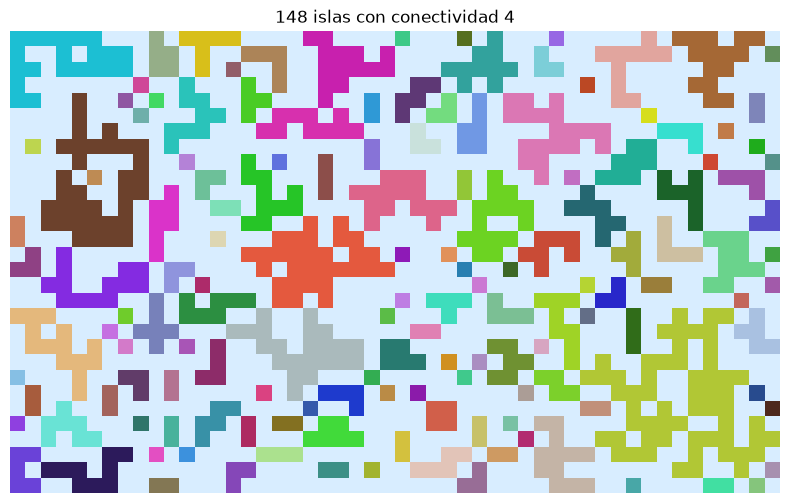

In [4]:
import random
import numpy as np
import matplotlib.pyplot as plt
from skimage.measure import label

random.seed(4)
grande = ["".join("#" if random.random() < 0.45 else "." for _ in range(50)) for _ in range(30)]
encontradas = islas(grande)
etiquetas = np.zeros((30, 50), dtype=int)
for numero, celdas in enumerate(encontradas, start=1):
    for f, c in celdas:
        etiquetas[f, c] = numero

referencia = label(np.array([[x == "#" for x in fila] for fila in grande]), connectivity=1)
assert referencia.max() == len(encontradas) == cuenta_islas(grande)
assert sorted(np.bincount(referencia.ravel())[1:]) == sorted(len(c) for c in encontradas)

mayor = max(encontradas, key=len)
print(len(encontradas), "islas; la mayor tiene área", len(mayor), "y perímetro", perimetro(grande, mayor))

colores = np.random.default_rng(0).uniform(0.1, 0.9, (len(encontradas) + 1, 3))
colores[0] = [0.85, 0.93, 1]  # agua
fig, eje = plt.subplots(figsize=(10, 6))
eje.imshow(colores[etiquetas])
eje.set_title(f"{len(encontradas)} islas con conectividad 4")
eje.axis("off")
plt.show()